# Data Exploration Report: IC-Patiëntendata — BP1

Dit notebook bevat een **data exploration report** voor de IC-patiëntendata die wordt gebruikt voor het IC-dashboard (bp1). De data bestaat uit drie bronnen:

| Bron | Beschrijving |
|------|--------------|
| **EPD-data** | Demografische patiëntgegevens en klinische observaties (SQL DML-script) |
| **Machine data** | Time-series metingen van vitale parameters en vloeistofbalans per IC-machine (CSV) |
| **Patient-machine mapping** | Koppeling van patiënten aan machines en bednummers (CSV) |

De requirements voor het dashboard staan beschreven in `doc/requirements.md`.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Visuele stijl instellen
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Basispad voor de databestanden (relatief aan de notebooks-map)
DATA_DIR = Path("../data")
MACHINE_DIR = DATA_DIR / "machine_data"
SCRIPTS_DIR = Path("../scripts")

## 1. EPD-data

De EPD-data (Electronic Patient Dossier) is opgeslagen als SQL INSERT-statements in `scripts/dml_epd_bp1.sql`. Hieronder worden de patiëntgegevens (tabel `patient`) en de klinische observaties (tabel `patient_observation`) geparsed met behulp van reguliere expressies (regex).

De velden zijn conform het DDL in `scripts/ddl_epd_bp1.sql`:

| Tabel | Velden |
|-------|--------|
| `patient` | `pid`, `firstname`, `lastname`, `dob`, `treatment` |
| `patient_observation` | `poid`, `pid`, `note_ts`, `note_text`, `pain_score` |

In [2]:
# Lees het DML SQL-bestand in als tekst
sql_text = (SCRIPTS_DIR / "dml_epd_bp1.sql").read_text(encoding="utf-8")

# ── Tabel: patient ────────────────────────────────────────────────────────
# Elke rij heeft de vaste structuur:
#   (pid, 'voornaam', 'achternaam', 'geboortedatum', 'behandeling')
# De behandeling bevat geen enkele aanhalingstekens, dus [^']+ volstaat.
patient_pattern = re.compile(
    r"[(](\d+),\s*'([^']+)',\s*'([^']+)',\s*'(\d{4}-\d{2}-\d{2})',\s*'([^']+)'[)]"
)
patient_matches = patient_pattern.findall(sql_text)

df_patient = pd.DataFrame(
    patient_matches,
    columns=["pid", "firstname", "lastname", "dob", "treatment"],
)
df_patient["pid"] = df_patient["pid"].astype(int)
df_patient["dob"] = pd.to_datetime(df_patient["dob"])

# ── Tabel: patient_observation ────────────────────────────────────────────
# Elke observatie beslaat drie regels in het SQL-script:
#   Regel 1: (poid, pid, 'note_ts',
#   Regel 2:  'note_text (kan '' bevatten voor escaped quotes)',
#   Regel 3:  pain_score),
#
# Strategie: extraheer de header (poid, pid, note_ts) en de pain_score apart
# via aparte regex-patronen en combineer ze op volgorde.

# Patroon 1: eerste drie velden van elke observatierij
obs_header_pattern = re.compile(
    r"[(](\d+),\s+(\d+),\s+'(\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})'"
)
obs_headers = obs_header_pattern.findall(sql_text)

# Patroon 2: pain_score — staat op een eigen regel vlak voor de afsluitende
# haakjes: '\n pain_score)' in het INSERT-blok voor patient_observation.
# We isoleren eerst het INSERT-blok om ongewenste matches te vermijden.
obs_block_match = re.search(
    r"INSERT INTO patient_observation.*?VALUES(.*?);\s*$",
    sql_text,
    re.DOTALL | re.MULTILINE,
)
pain_scores = []
if obs_block_match:
    obs_block = obs_block_match.group(1)
    # De pain_score staat aan het begin van een regel (na witruimte),
    # gevolgd door ')' (en eventueel een komma).
    pain_scores = [
        int(m) for m in re.findall(r"^\s+(\d+)[)]", obs_block, re.MULTILINE)
    ]

# Combineer header en pain_score op volgorde
obs_records = [
    {
        "poid": int(h[0]),
        "pid": int(h[1]),
        "note_ts": pd.to_datetime(h[2]),
        "pain_score": ps,
    }
    for h, ps in zip(obs_headers, pain_scores)
]
df_observation = pd.DataFrame(obs_records)

print(f"Patiënten ingeladen  : {len(df_patient)}")
print(f"Observaties ingeladen: {len(df_observation)}")

Patiënten ingeladen  : 20
Observaties ingeladen: 20


### 1.1 Pain scores

De histogram toont de verdeling van de pain scores (NRS 0–10) over alle IC-patiënten bij opname. Een score van 0 wordt doorgaans geregistreerd bij gesedeerde of bewusteloze patiënten.

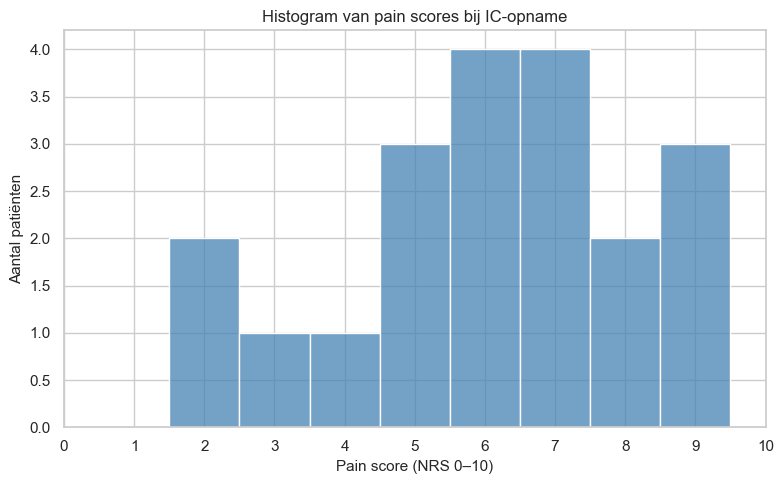

In [3]:
# Histogram van de pain scores bij IC-opname
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    df_observation["pain_score"],
    ax=ax,
    discrete=True,   # Behandel de integer scores als discrete waarden
    color="steelblue",
    edgecolor="white",
)
ax.set_xlabel("Pain score (NRS 0–10)", fontsize=11)
ax.set_ylabel("Aantal patiënten", fontsize=11)
ax.set_title("Histogram van pain scores bij IC-opname", fontsize=12)
ax.set_xticks(range(0, 11))

plt.tight_layout()
plt.show()

## 2. Machine Data — Geaggregeerde Analyse

De machine data bestaat uit time-series metingen per IC-machine. Elke machine registreert de volgende parameters minuut-voor-minuut over een periode van 30 minuten:

| Veld | Beschrijving | Eenheid |
|------|--------------|---------|
| `TS` | Tijdstempel van de meting | datetime |
| `SBP` | Systolic Blood Pressure (bovendruk) | mmHg |
| `DBP` | Diastolic Blood Pressure (onderdruk) | mmHg |
| `HR` | Heart Rate (hartslag) | bpm |
| `Fluids` | Vloeistoffen toegediend | ml/min |
| `BloodLost` | Bloed verloren | ml/min |
| `BloodGiven` | Bloed toegediend | ml/min |

Hieronder worden alle 20 machine CSV-bestanden samengevoegd en geanalyseerd.

In [4]:
# Laad de patient-machine mapping (benodigd voor de individuele patiëntgrafieken)
df_mapping = pd.read_csv(DATA_DIR / "patient_machine_mapping.csv")
# Normaliseer kolomnamen naar lowercase voor consistentie
df_mapping.columns = df_mapping.columns.str.lower()

# Laad alle machine CSV-bestanden en combineer ze in één DataFrame
machine_dfs = []
for csv_file in sorted(MACHINE_DIR.glob("machine_*.csv")):
    # Extraheer het machine-ID uit de bestandsnaam (bijv. 'M01' uit 'machine_M01.csv')
    machine_id = csv_file.stem.replace("machine_", "")
    df_temp = pd.read_csv(csv_file, parse_dates=["TS"])
    df_temp["MID"] = machine_id  # Voeg machine-ID toe als extra kolom
    machine_dfs.append(df_temp)

df_all = pd.concat(machine_dfs, ignore_index=True)

print(f"Totaal aantal metingen : {len(df_all):,}")
print(f"Tijdsperiode           : {df_all['TS'].min()} — {df_all['TS'].max()}")
print(f"Aantal unieke machines : {df_all['MID'].nunique()}")
print(f"Kolommen               : {list(df_all.columns)}")

Totaal aantal metingen : 593
Tijdsperiode           : 2026-05-11 06:00:00 — 2026-05-11 12:29:00
Aantal unieke machines : 20
Kolommen               : ['TS', 'SBP', 'DBP', 'HR', 'Fluids', 'BloodLost', 'BloodGiven', 'MID']


### 2.1 Descriptieve statistieken (alle machines gecombineerd)

Onderstaande tabel toont de mean, median, standard deviation, minimum en maximum van elk meetveld, alsmede het aantal missing values.

In [5]:
# Numerieke meetvelden
METRIC_COLS = ["SBP", "DBP", "HR", "Fluids", "BloodLost", "BloodGiven"]

# Bereken descriptieve statistieken
stats = df_all[METRIC_COLS].agg(["mean", "median", "std", "min", "max"])
missing = df_all[METRIC_COLS].isnull().sum().rename("missing values")

# Samenvoegen in één overzichtstabel
stats_table = pd.concat([stats.T, missing], axis=1)
stats_table.columns = [
    "Mean", "Median", "Std. deviation", "Minimum", "Maximum", "Missing values"
]

print("=== Geaggregeerde statistieken — alle machine data ===")
stats_table.round(3)

=== Geaggregeerde statistieken — alle machine data ===


,Mean,Median,Std. deviation,Minimum,Maximum,Missing values
SBP,120.954,118.40,24.122,90.0,175.20,0
DBP,71.949,69.40,10.878,60.0,103.60,0
HR,100.507,98.55,21.739,50.0,138.50,1
Fluids,2.344,2.18,0.870,1.0,4.72,0
BloodLost,1.767,1.55,1.084,0.0,4.98,0
BloodGiven,1.431,1.38,1.229,0.0,4.83,0


### 2.2 Distributie van meetvelden

Voor velden met een **absolute skewness > 1,0** wordt een histogram gebruikt (sterk scheve verdeling); voor de overige velden een boxplot. Outliers in de boxplots zijn als individuele punten weergegeven.

> **Noot:** SBP en DBP (bloeddruk) worden altijd met hetzelfde grafiektype weergegeven: als één van beide een histogram krijgt op basis van de skewness, geldt dat automatisch ook voor het andere bloeddruk-veld.

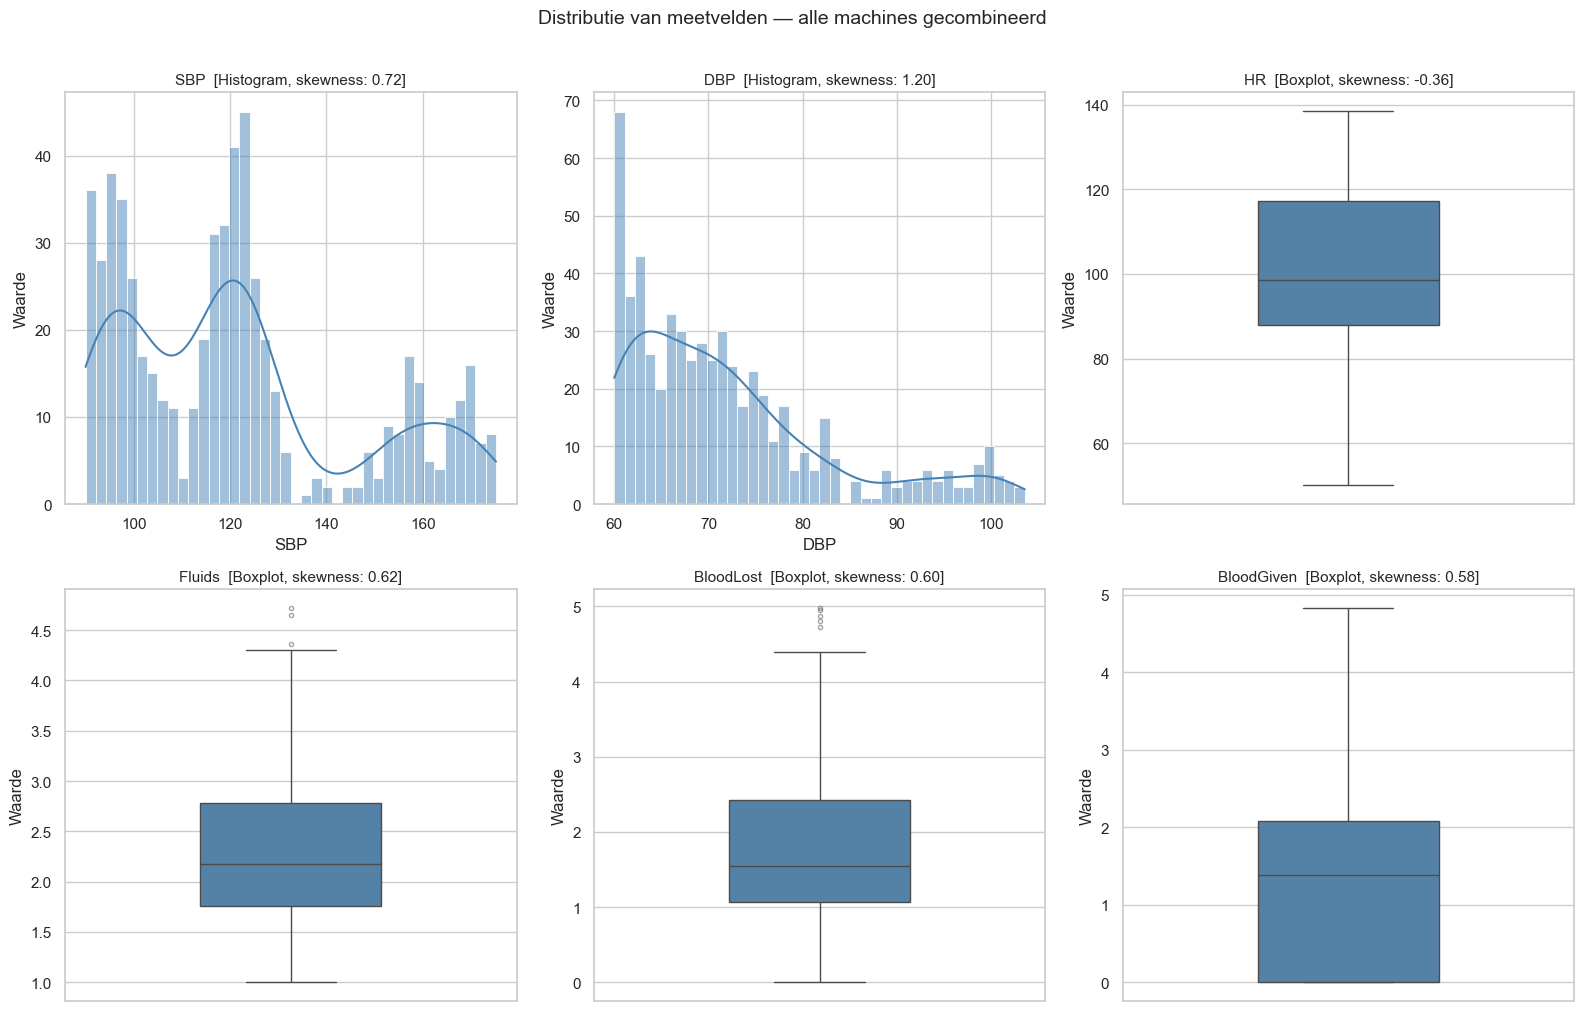

Outlier-analyse (IQR-methode, 1.5× IQR):
  SBP         : skewness=+0.72, outliers=13 (2.2%)
  DBP         : skewness=+1.20, outliers=37 (6.2%)
  HR          : skewness=-0.36, outliers=0 (0.0%)
  Fluids      : skewness=+0.62, outliers=3 (0.5%)
  BloodLost   : skewness=+0.60, outliers=5 (0.8%)
  BloodGiven  : skewness=+0.58, outliers=0 (0.0%)


In [6]:
# Bereken de skewness per meetveld om de juiste visualisatie te kiezen
skewness = df_all[METRIC_COLS].skew()
SKEWNESS_THRESHOLD = 1.0

# Bepaal welke velden een histogram krijgen op basis van skewness
histogram_fields = {col for col in METRIC_COLS if abs(skewness[col]) > SKEWNESS_THRESHOLD}

# Speciale regel: SBP en DBP (bloeddruk) krijgen altijd hetzelfde grafiektype.
# Als één van beide een histogram krijgt, geldt dat voor beide.
if "SBP" in histogram_fields or "DBP" in histogram_fields:
    histogram_fields.update(["SBP", "DBP"])

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(METRIC_COLS):
    ax = axes[i]
    skew_val = skewness[col]
    data = df_all[col].dropna()

    if col in histogram_fields:
        # Histogram voor sterk scheve verdelingen (of bloeddruk-veld gekoppeld aan scheef veld)
        sns.histplot(data, ax=ax, bins=40, kde=True,
                     color="steelblue", edgecolor="white")
        plot_type = "Histogram"
    else:
        # Boxplot voor min of meer symmetrische verdelingen
        sns.boxplot(
            y=data, ax=ax, color="steelblue", width=0.4,
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.5},
        )
        plot_type = "Boxplot"

    ax.set_title(f"{col}  [{plot_type}, skewness: {skew_val:.2f}]", fontsize=11)
    ax.set_ylabel("Waarde")

plt.suptitle(
    "Distributie van meetvelden — alle machines gecombineerd",
    fontsize=14, y=1.01,
)
plt.tight_layout()
plt.show()

# ── Overzicht outliers ────────────────────────────────────────────────────
print("Outlier-analyse (IQR-methode, 1.5× IQR):")
for col in METRIC_COLS:
    q1, q3 = df_all[col].quantile(0.25), df_all[col].quantile(0.75)
    iqr = q3 - q1
    n_outliers = int(
        ((df_all[col] < q1 - 1.5 * iqr) | (df_all[col] > q3 + 1.5 * iqr)).sum()
    )
    pct = 100 * n_outliers / len(df_all)
    print(
        f"  {col:<12s}: skewness={skewness[col]:+.2f}, "
        f"outliers={n_outliers} ({pct:.1f}%)"
    )

### 2.3 Correlation matrix

De correlation matrix toont de Pearson-correlaties tussen de meetvelden. Een heatmap maakt sterke en zwakke correlaties snel zichtbaar. De bovenste driehoek is verborgen (spiegelbeeldig).

Relevante correlaties voor het dashboard:
- **SBP ↔ DBP**: een fysiologisch verwachte positieve correlatie bevestigt de   datakwaliteit.
- **BloodLost ↔ BloodGiven**: patiënten die bloed verliezen worden doorgaans ook   getransfundeerd, wat een positieve correlatie verwacht doet zijn.

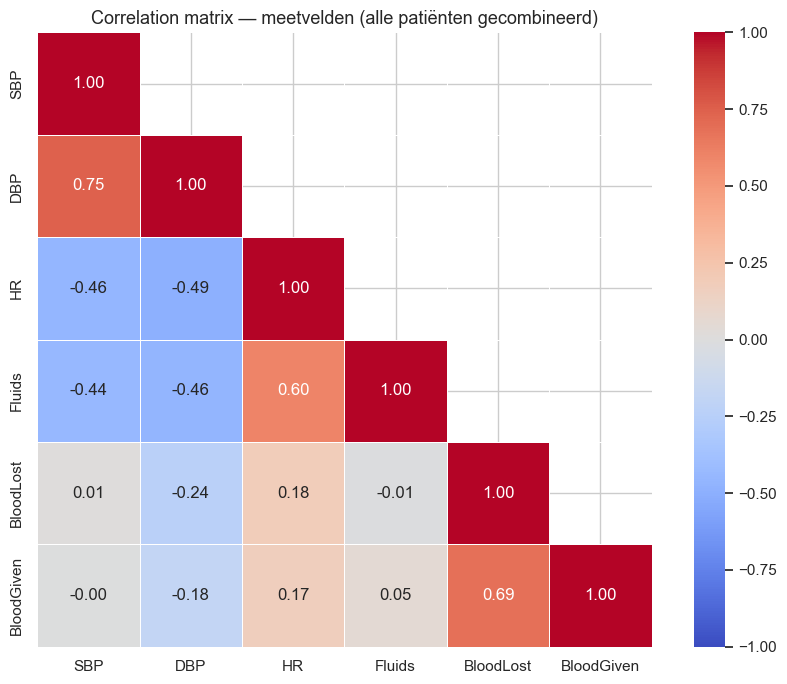

Opvallende correlaties (|r| > 0.4):
  SBP ↔ DBP: r = 0.75 (positief)
  SBP ↔ HR: r = -0.46 (negatief)
  SBP ↔ Fluids: r = -0.44 (negatief)
  DBP ↔ HR: r = -0.49 (negatief)
  DBP ↔ Fluids: r = -0.46 (negatief)
  HR ↔ Fluids: r = 0.60 (positief)
  BloodLost ↔ BloodGiven: r = 0.69 (positief)


In [7]:
# Bereken de Pearson correlation matrix
corr_matrix = df_all[METRIC_COLS].corr()

# Visualiseer als heatmap (alleen onderste driehoek + diagonaal)
fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True, fmt=".2f",
    cmap="coolwarm", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5,
    ax=ax,
)
ax.set_title(
    "Correlation matrix — meetvelden (alle patiënten gecombineerd)", fontsize=13
)
plt.tight_layout()
plt.show()

# ── Identificeer opvallende correlaties ──────────────────────────────────
print("Opvallende correlaties (|r| > 0.4):")
found = False
for i, col1 in enumerate(METRIC_COLS):
    for j, col2 in enumerate(METRIC_COLS):
        if i < j:
            r = corr_matrix.loc[col1, col2]
            if abs(r) > 0.4:
                direction = "positief" if r > 0 else "negatief"
                print(f"  {col1} ↔ {col2}: r = {r:.2f} ({direction})")
                found = True
if not found:
    print("  Geen opvallende correlaties (|r| > 0.4) gevonden.")

## 3. Machine Data — Individuele Patiënt Analyse

Per patiënt wordt een **time-series grafiek** getoond van alle zes meetvelden over de 30-minuten monitoringperiode.

- De **vitale parameters** SBP, DBP en HR worden op de **linker y-as** geplot   (schaal ~50–200 mmHg / bpm).
- De **vloeistofvelden** Fluids, BloodLost en BloodGiven worden op de   **rechter y-as** geplot (schaal ~0–5 ml/min).

De legenda toont per veld de **minimum, maximum en mean waarde** voor eenvoudige interpretatie.

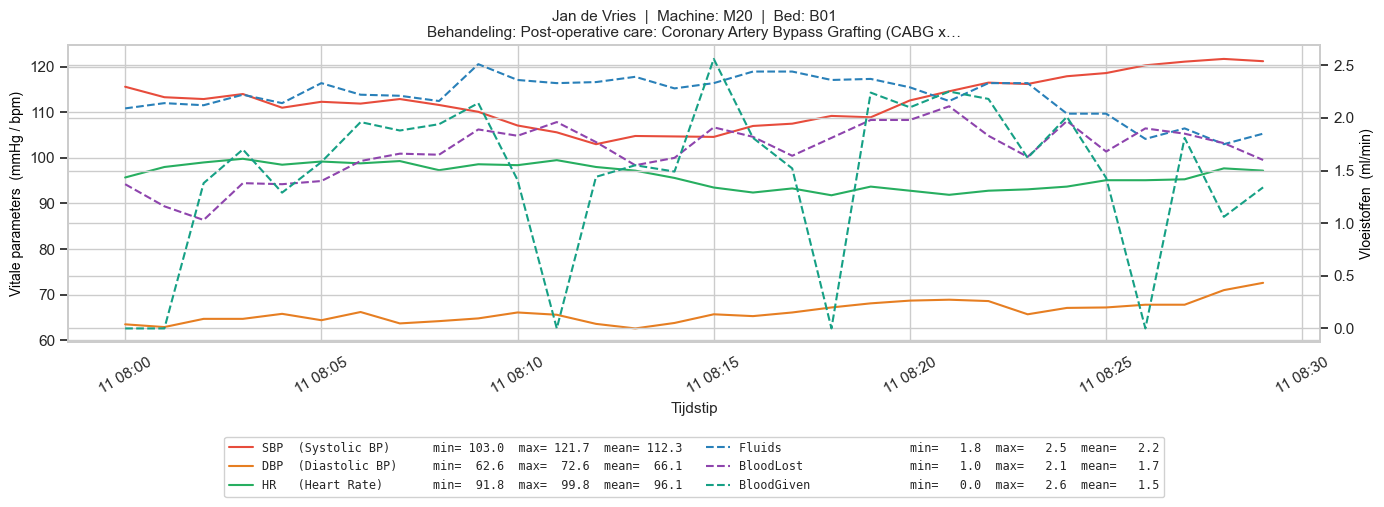

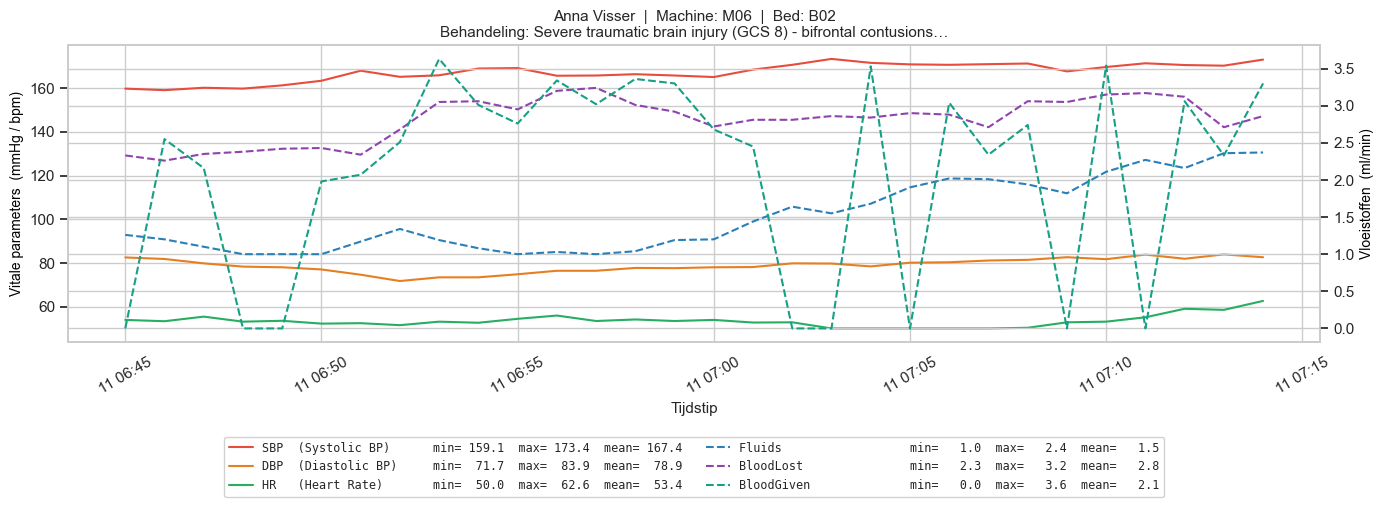

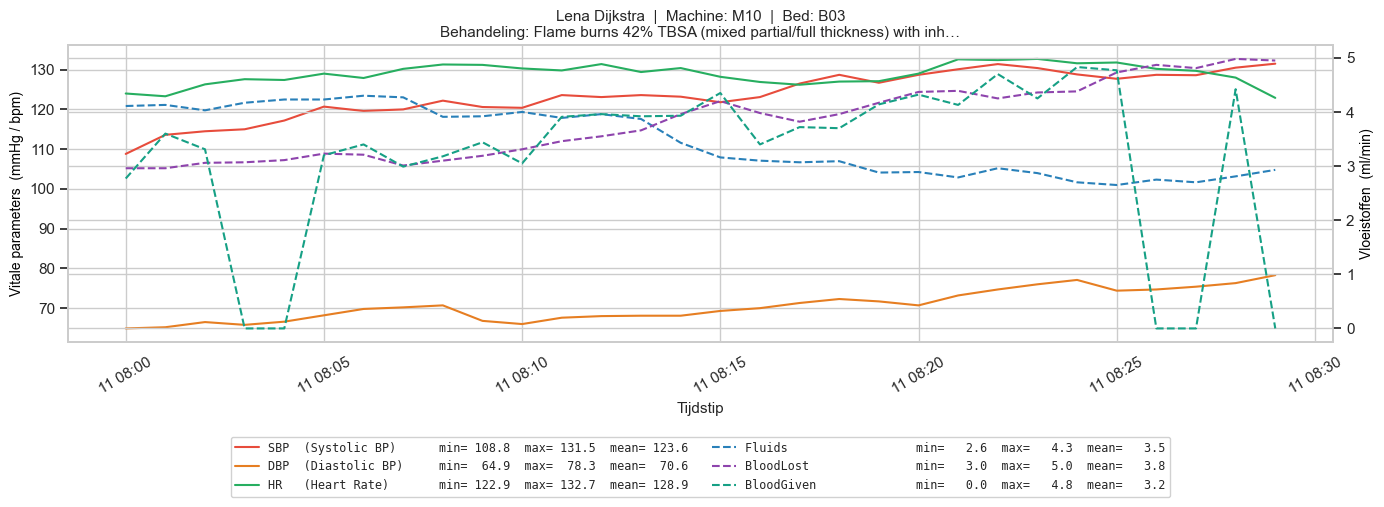

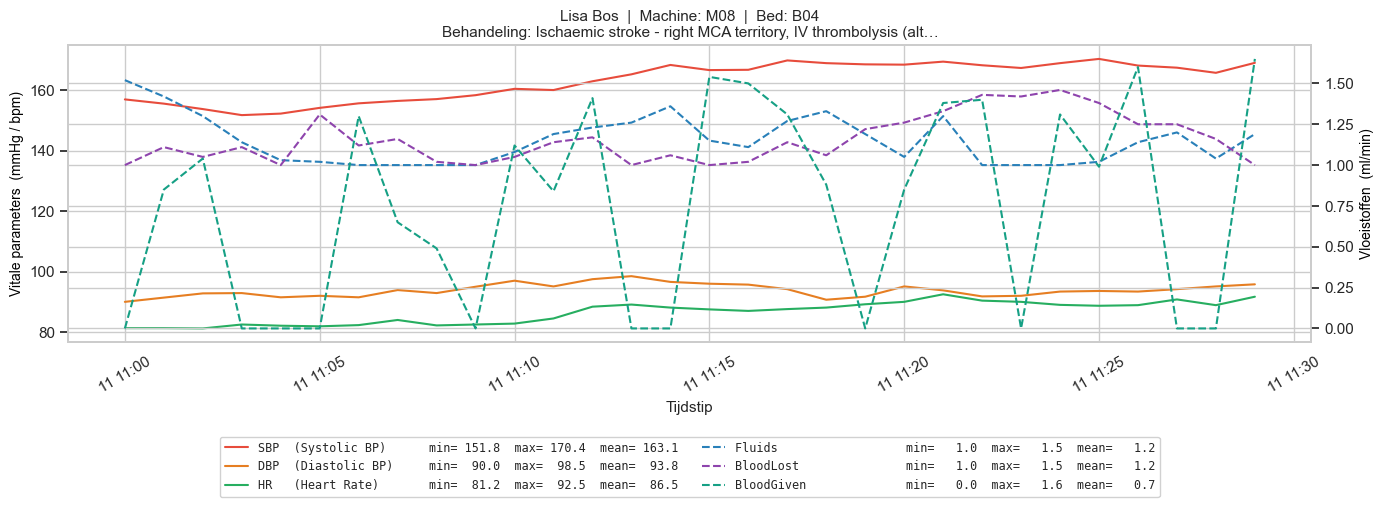

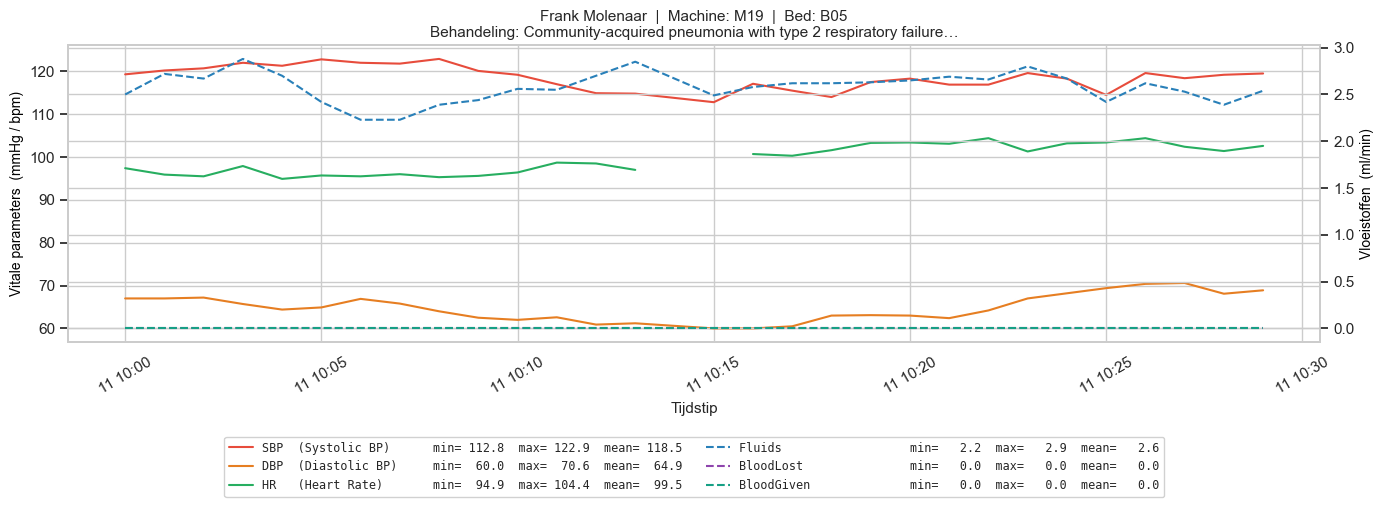

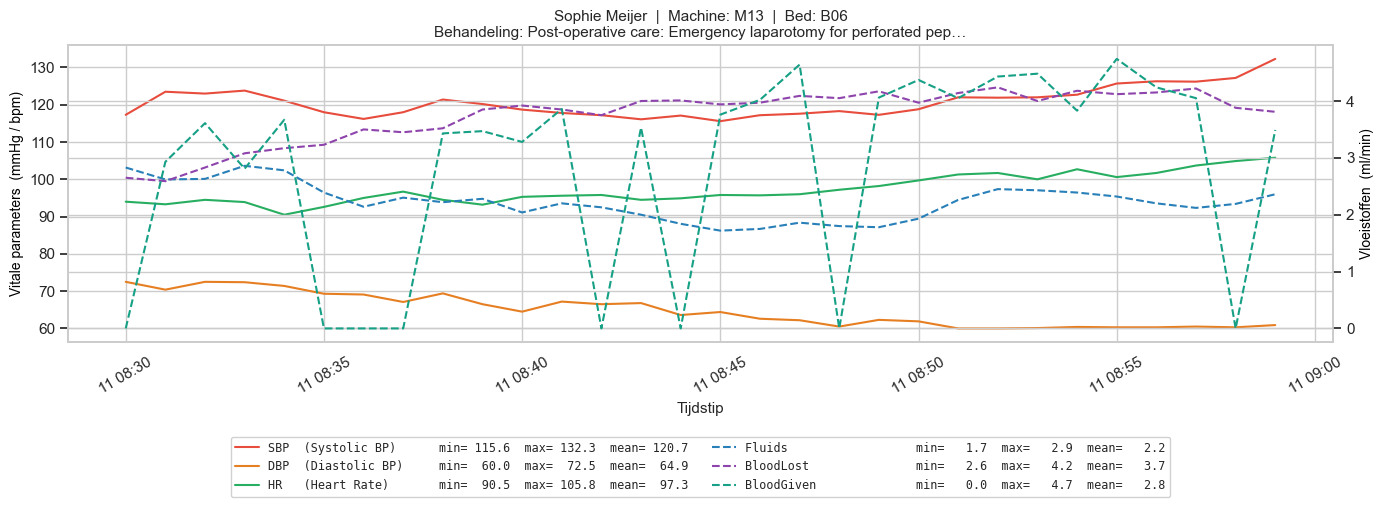

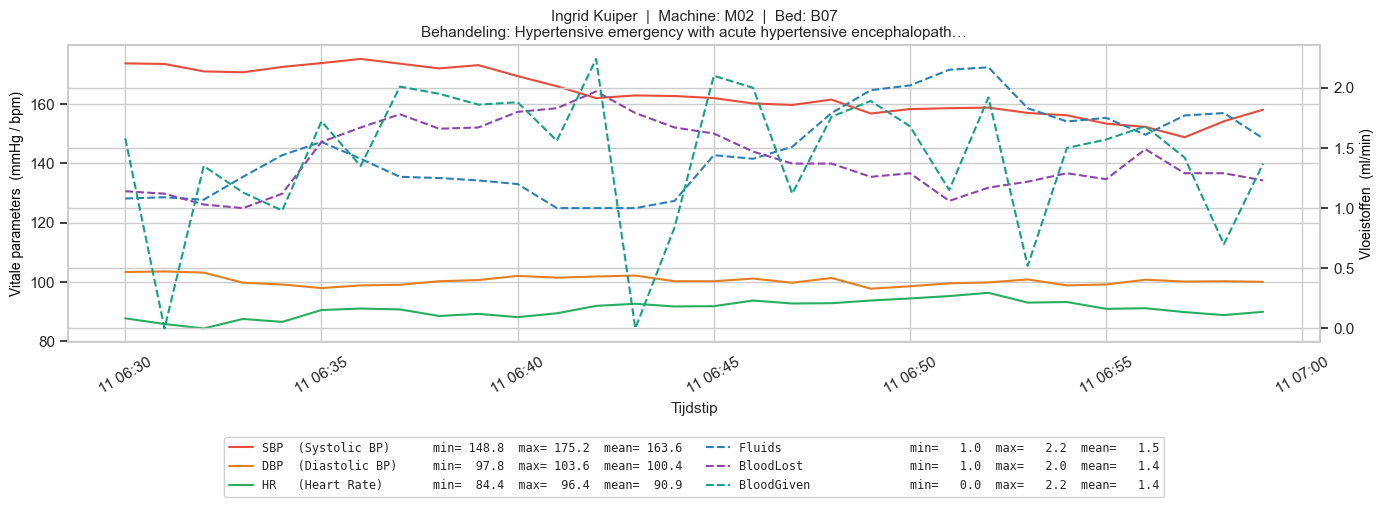

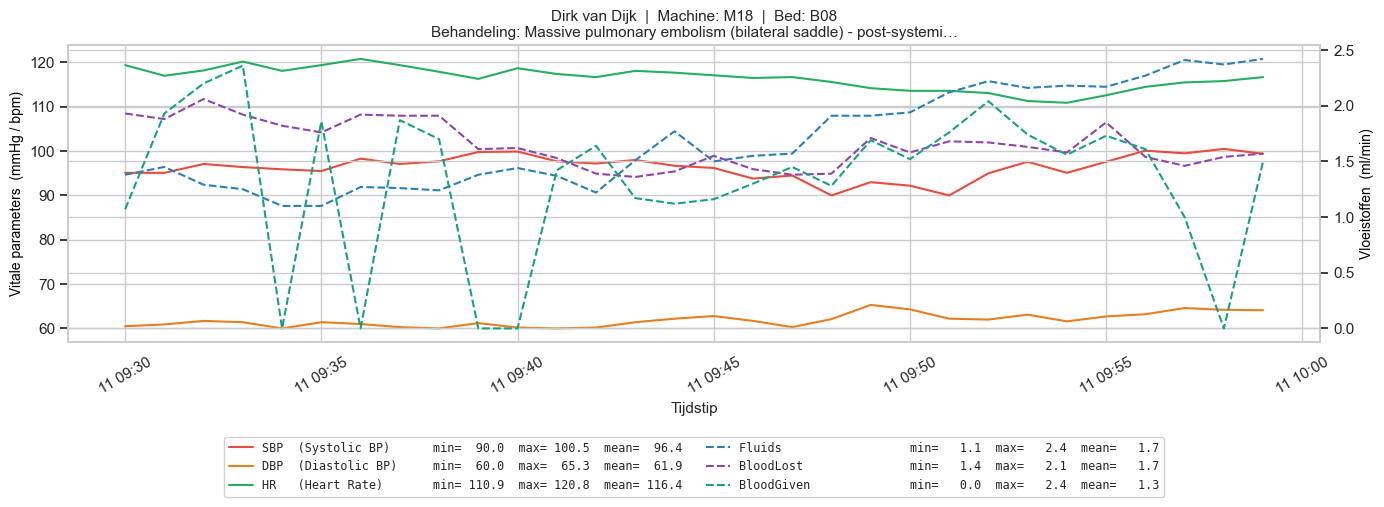

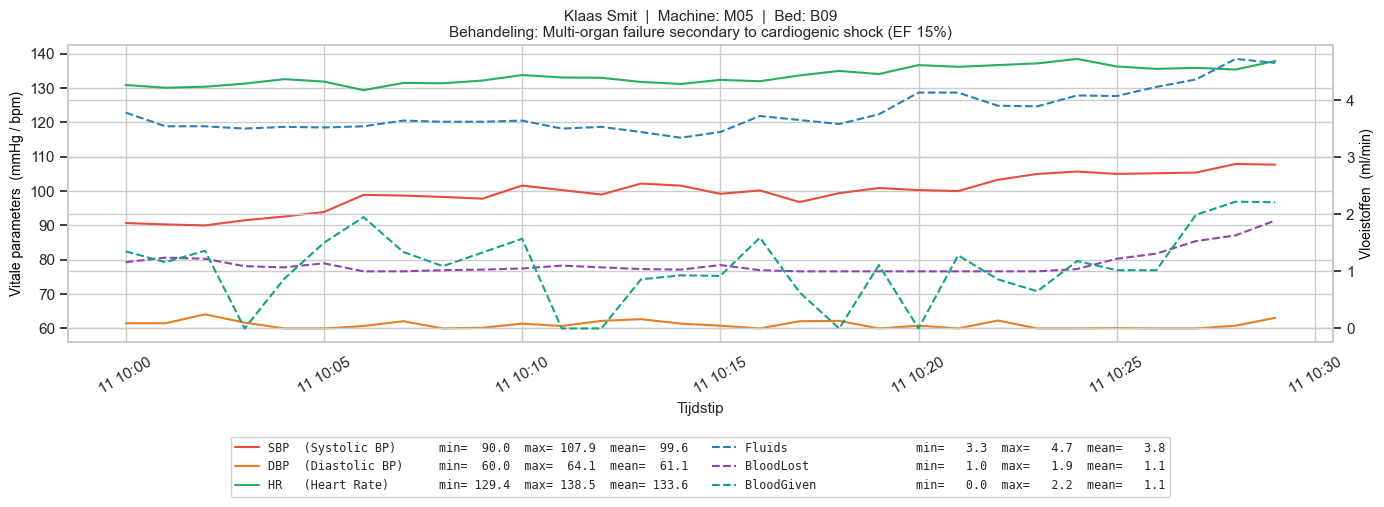

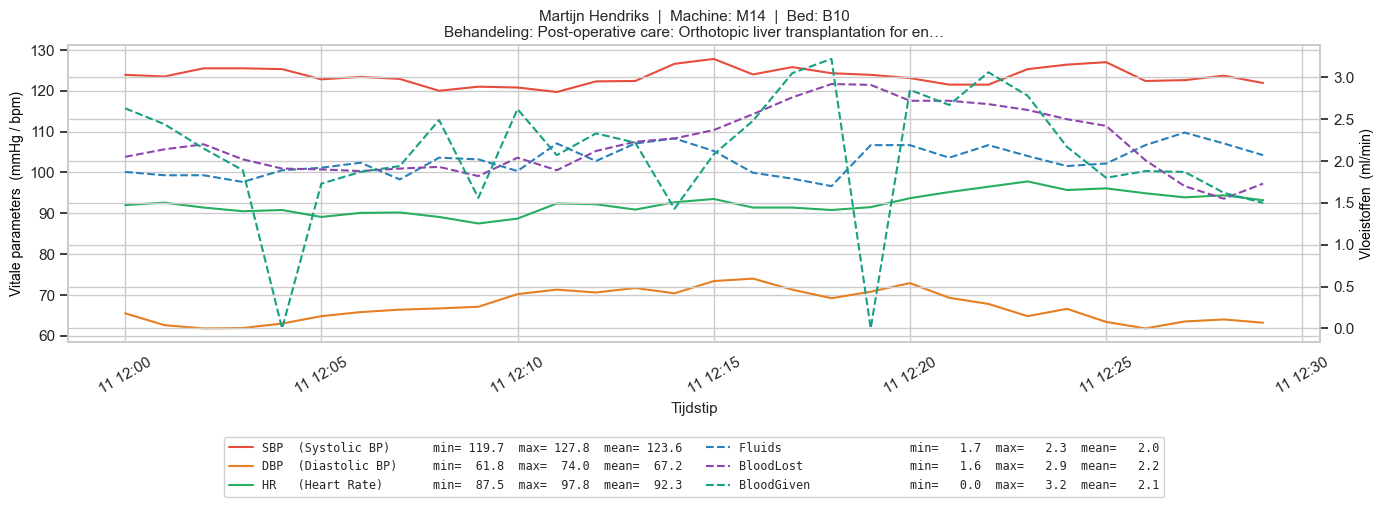

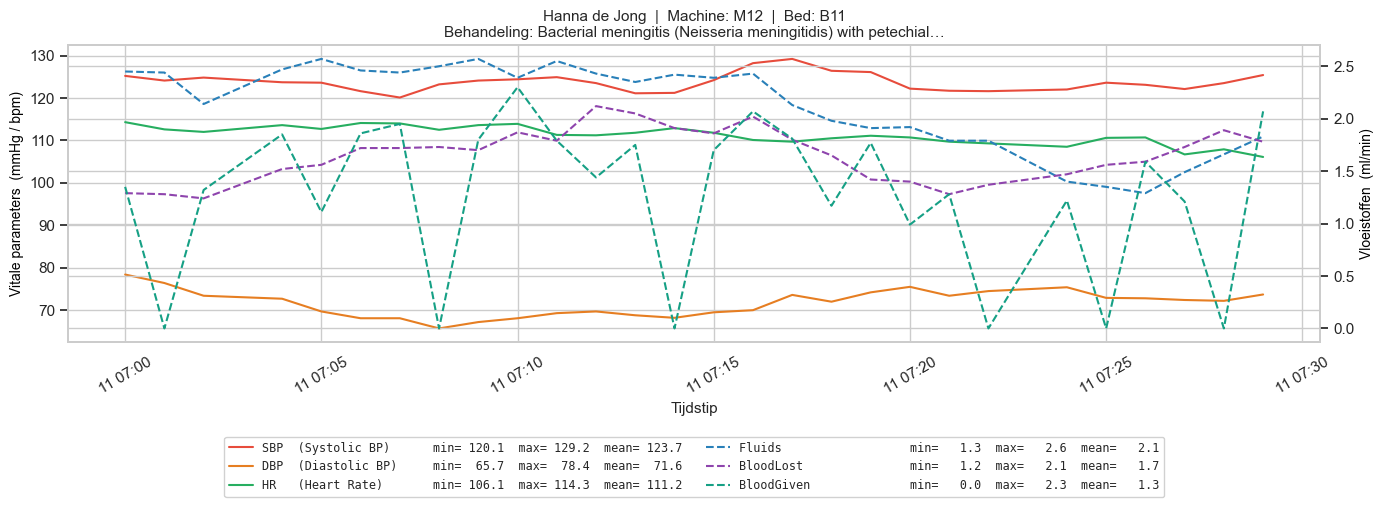

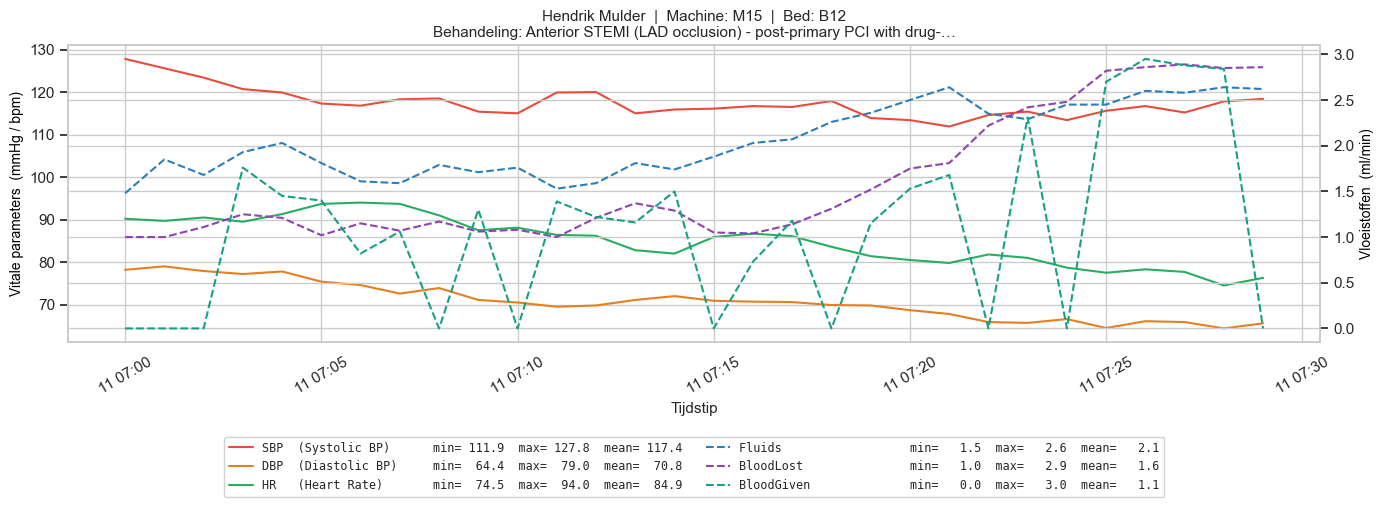

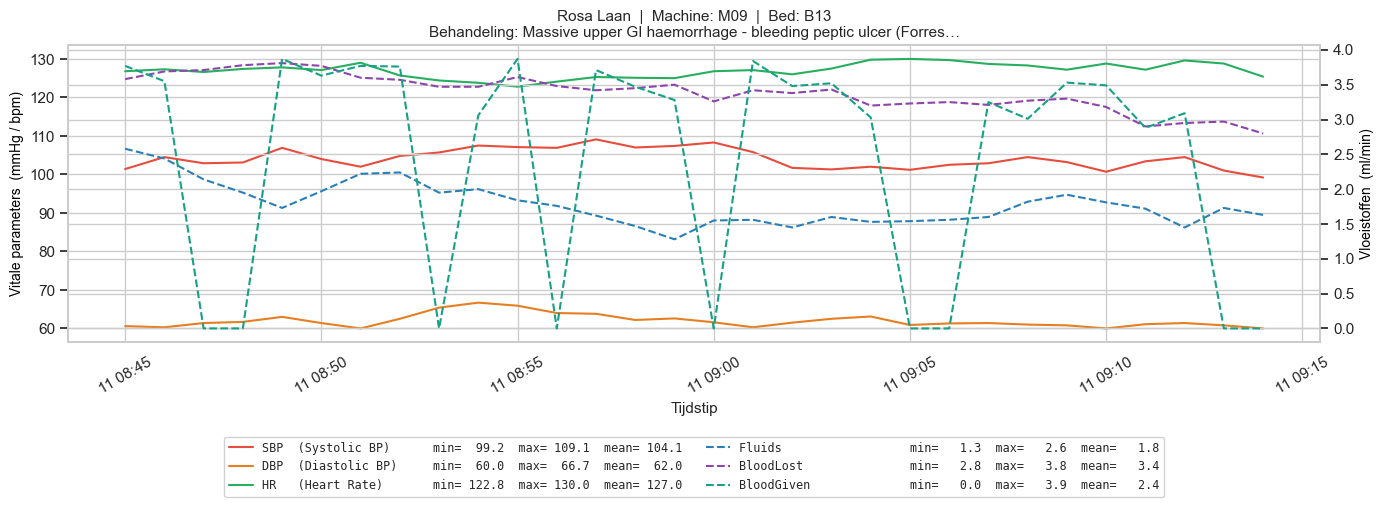

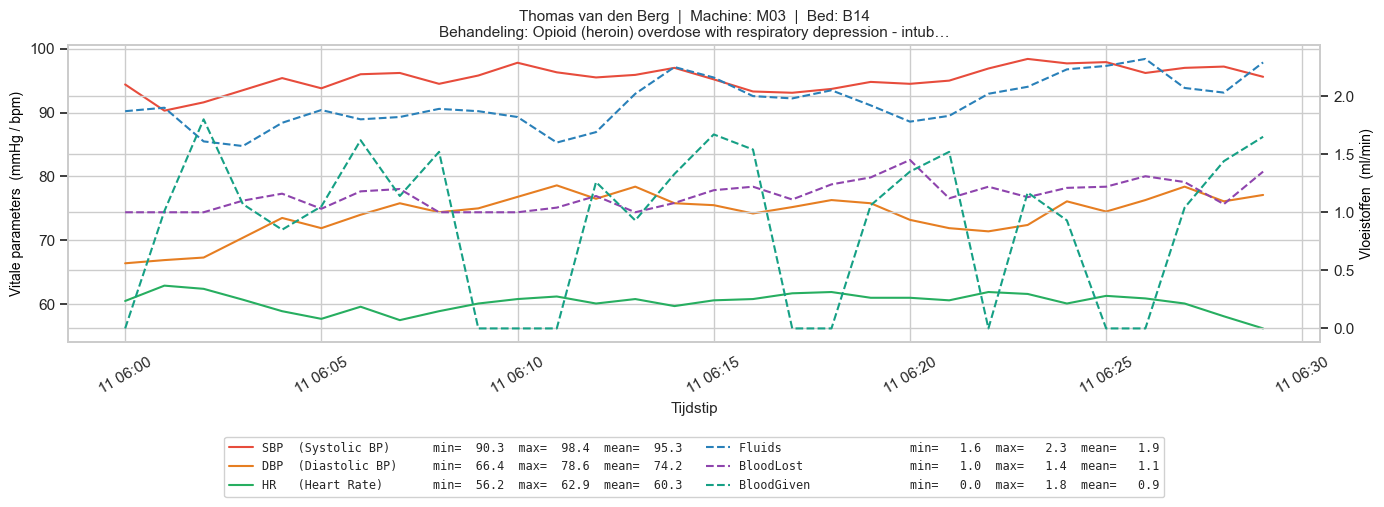

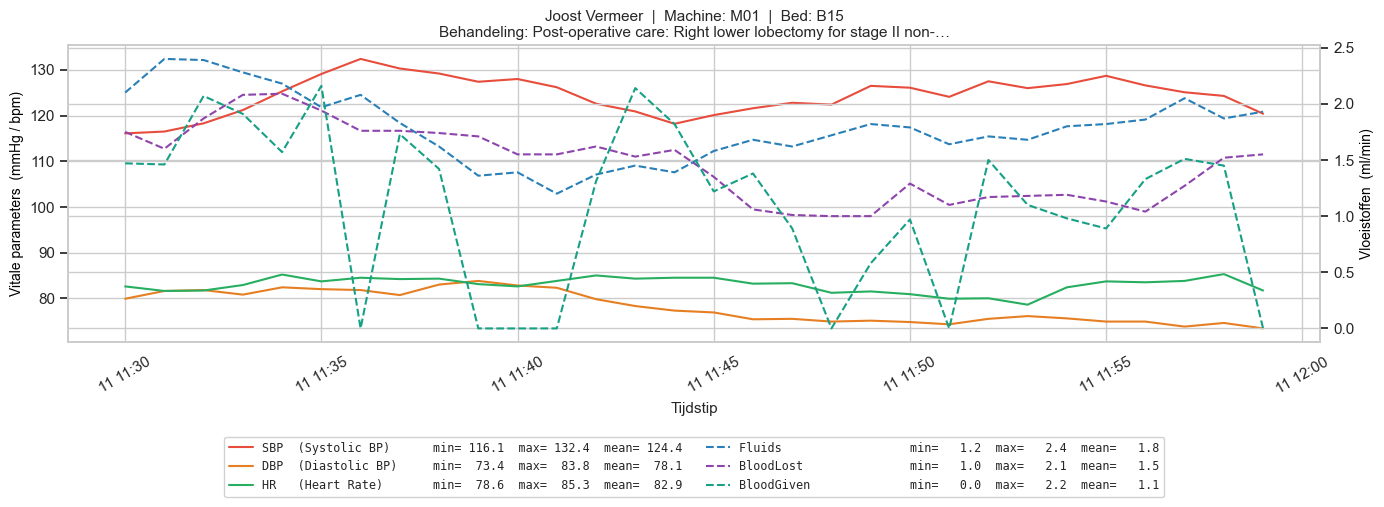

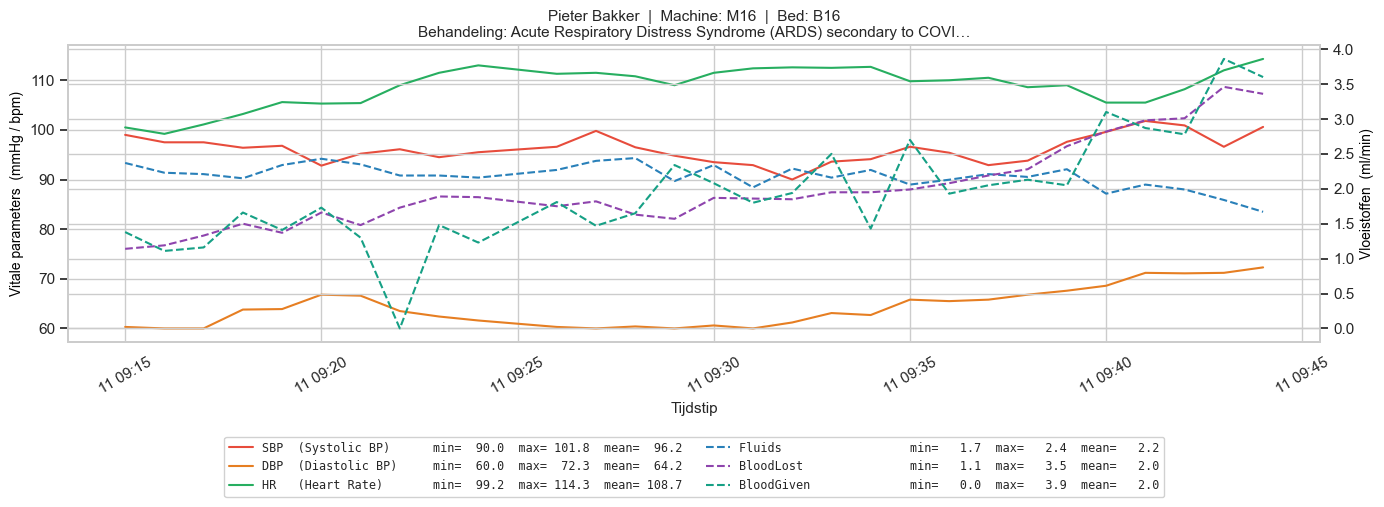

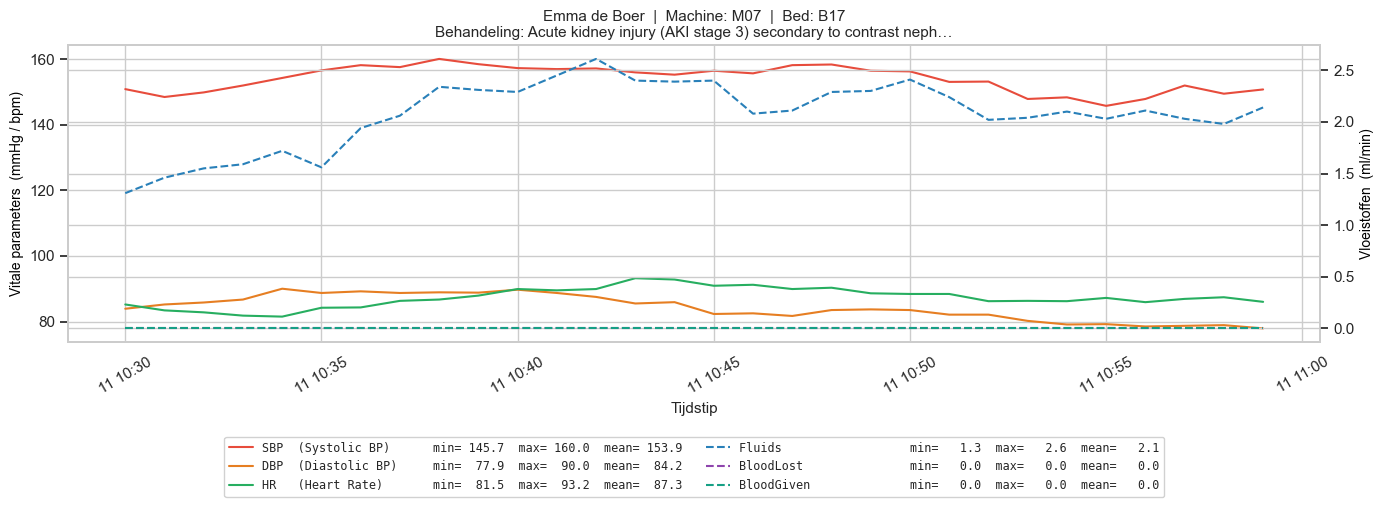

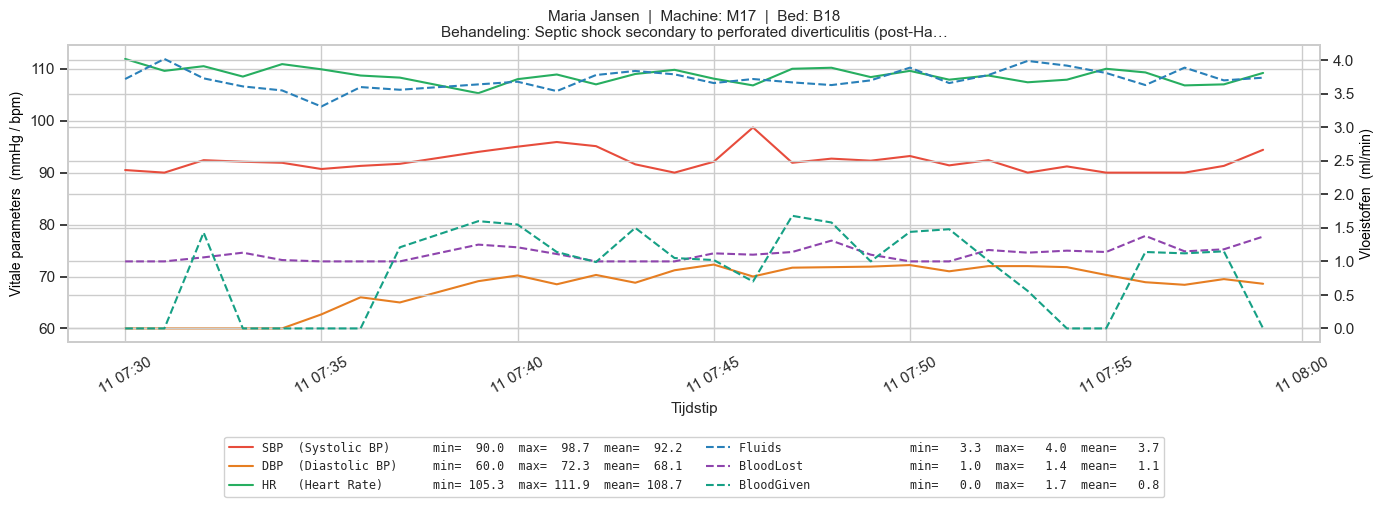

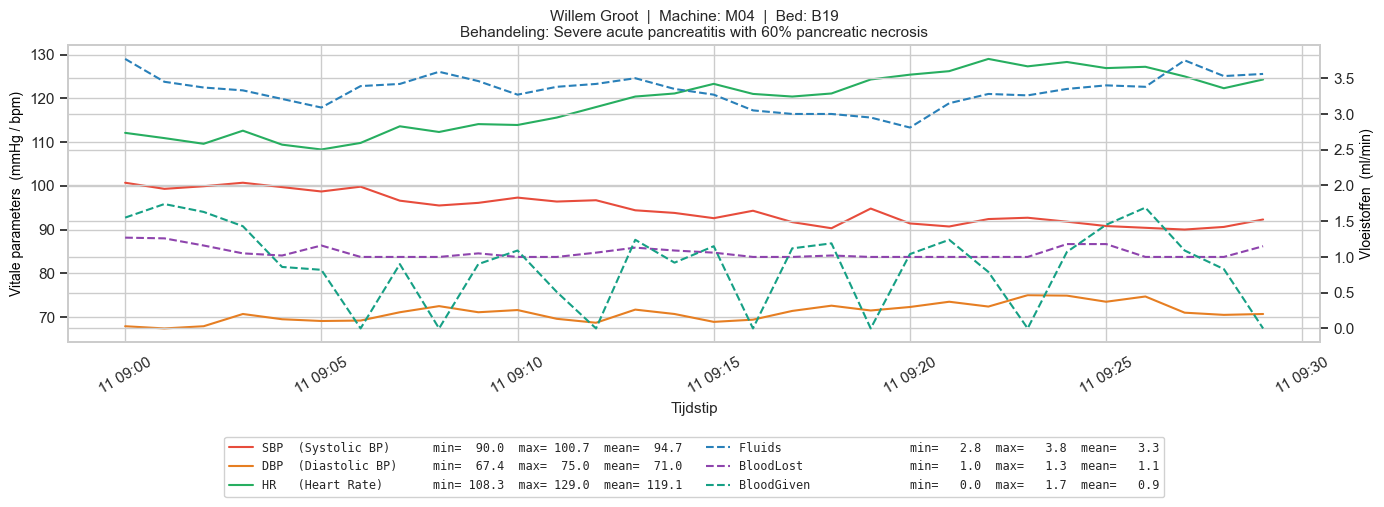

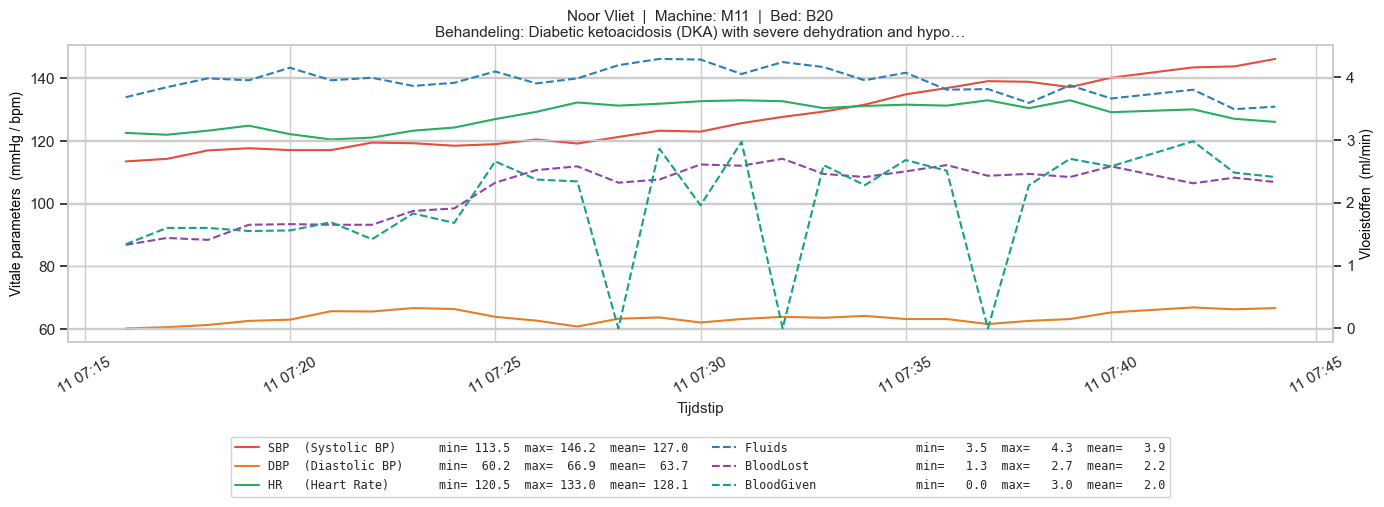

In [8]:
# Kleuren en lijnstijlen per meetveld
FIELD_STYLES = {
    "SBP":        {"color": "#e74c3c", "ls": "-",  "label": "SBP  (Systolic BP)"},
    "DBP":        {"color": "#e67e22", "ls": "-",  "label": "DBP  (Diastolic BP)"},
    "HR":         {"color": "#27ae60", "ls": "-",  "label": "HR   (Heart Rate)"},
    "Fluids":     {"color": "#2980b9", "ls": "--", "label": "Fluids"},
    "BloodLost":  {"color": "#8e44ad", "ls": "--", "label": "BloodLost"},
    "BloodGiven": {"color": "#16a085", "ls": "--", "label": "BloodGiven"},
}

# Verdeling over de twee y-assen
LEFT_FIELDS  = ["SBP", "DBP", "HR"]           # mmHg / bpm
RIGHT_FIELDS = ["Fluids", "BloodLost", "BloodGiven"]  # ml/min

# Loop door elke patiënt-machine combinatie, gesorteerd op bed-ID
for _, row in df_mapping.sort_values("bid").iterrows():
    pid_str = row["pid"]   # bijv. 'P13847'
    mid_str = row["mid"]   # bijv. 'M20'
    bid_str = row["bid"]   # bijv. 'B01'

    # Patiëntinformatie ophalen
    pid_int = int(pid_str.replace("P", ""))
    patient_row = df_patient[df_patient["pid"] == pid_int]
    if not patient_row.empty:
        p = patient_row.iloc[0]
        patient_name = f"{p['firstname']} {p['lastname']}"
        treatment_short = p["treatment"][:60] + "…" if len(p["treatment"]) > 60 else p["treatment"]
    else:
        patient_name = "Onbekend"
        treatment_short = ""

    # Machine data ophalen en sorteren op tijdstempel
    df_machine = df_all[df_all["MID"] == mid_str].sort_values("TS").copy()
    if df_machine.empty:
        print(f"Geen data gevonden voor machine {mid_str}")
        continue

    # ── Figuur aanmaken met twee y-assen ─────────────────────────────────
    fig, ax1 = plt.subplots(figsize=(14, 5))
    ax2 = ax1.twinx()

    legend_lines  = []
    legend_labels = []

    # Vitale parameters op linker y-as
    for col in LEFT_FIELDS:
        style  = FIELD_STYLES[col]
        values = df_machine[col]
        col_min, col_max, col_mean = values.min(), values.max(), values.mean()
        lbl = (
            f"{style['label']:<22s}"
            f"  min={col_min:6.1f}  max={col_max:6.1f}  mean={col_mean:6.1f}"
        )
        line, = ax1.plot(
            df_machine["TS"], values,
            color=style["color"], linestyle=style["ls"], linewidth=1.5,
        )
        legend_lines.append(line)
        legend_labels.append(lbl)

    # Vloeistofvelden op rechter y-as
    for col in RIGHT_FIELDS:
        style  = FIELD_STYLES[col]
        values = df_machine[col]
        col_min, col_max, col_mean = values.min(), values.max(), values.mean()
        lbl = (
            f"{style['label']:<22s}"
            f"  min={col_min:6.1f}  max={col_max:6.1f}  mean={col_mean:6.1f}"
        )
        line, = ax2.plot(
            df_machine["TS"], values,
            color=style["color"], linestyle=style["ls"], linewidth=1.5,
        )
        legend_lines.append(line)
        legend_labels.append(lbl)

    # ── Aslabels en opmaak ────────────────────────────────────────────────
    ax1.set_xlabel("Tijdstip", fontsize=11)
    ax1.set_ylabel("Vitale parameters  (mmHg / bpm)", fontsize=10, color="black")
    ax2.set_ylabel("Vloeistoffen  (ml/min)", fontsize=10, color="black")
    ax1.tick_params(axis="x", rotation=30)

    ax1.set_title(
        f"{patient_name}  |  Machine: {mid_str}  |  Bed: {bid_str}\n"
        f"Behandeling: {treatment_short}",
        fontsize=11,
    )

    # Gecombineerde legenda onder de grafiek (monospace font voor uitlijning)
    ax1.legend(
        legend_lines, legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.30),
        ncol=2,
        fontsize=8.5,
        framealpha=0.9,
        prop={"family": "monospace", "size": 8.5},
    )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.30)
    plt.show()